## Stage 2: Model Building & Validation

### 1. Project Objective

The objective of Stage 2 is to develop and evaluate a baseline
machine learning model that predicts whether a policyholder is
likely to file an insurance claim.

We will use the cleaned and feature-engineered dataset produced
during Stage 1.

### Business Goal

Help SafeDrive Insurance identify policyholders who may be more
likely to file claims, enabling the underwriting and risk management
teams to investigate risk patterns and make better-informed decisions.

### Modelling Approach

We will use Logistic Regression as the baseline classification
model. Its performance will be evaluated using a held-out test
dataset and cross-validation.

Further this model will be used to compare with Decision Tree in the next stage of this project

### Target Variable

`is_claim`

- `0` — No claim filed
- `1` — Claim filed

#### 1.0: Importing important libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,# used because target is imbalanced, and we want to do multiple training on the model
    #with different splits and then check the avg results
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

RANDOM_STATE = 42
TARGET = "is_claim"

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


#### 1.2. Loading the feature engineered dataset

In [2]:
from pathlib import Path
import pandas as pd

candidate_paths = [
    Path(r"D:\UPGRAD\CapStone_Project\insurance_stage1_cleaned.csv"),
    Path.cwd() / "insurance_stage1_cleaned.csv",
    Path("/mnt/data/insurance_stage1_cleaned.csv")
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "insurance_stage1_cleaned.csv was not found. Run Notebook 1 first "
        "and keep its exported CSV beside this notebook."
    )

df = pd.read_csv(DATA_PATH)
print("Loaded Stage 1 dataset from:", DATA_PATH.resolve())
print("Dataset shape:", df.shape)
display(df.head())

Loaded Stage 1 dataset from: D:\UPGRAD\CapStone_Project\insurance_stage1_cleaned.csv
Dataset shape: (58592, 49)


,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim,max_power_bhp,max_torque_nm,safety_equipment_count,power_to_weight,High_Risk_Driver_Flag
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,0,0,0,1,0,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0,40.36,60.0,3,0.034059,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,0,0,0,1,0,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0,40.36,60.0,3,0.034059,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,0,0,0,1,0,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,0,40.36,60.0,3,0.034059,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,1,1,0,1,1,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,1,0,0,1,1,1,1,1,1,1,1,1,2,0,88.50,113.0,14,0.066292,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,0,0,0,0,1,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,0,0,0,0,0,1,1,1,0,1,1,1,2,0,67.06,91.0,7,0.058061,0


#### 1.3. Checking the engineered dataset before proceeding

In [3]:
print("Column Count:", len(df.columns))

print("\nTarget Distribution:")
display(df["is_claim"].value_counts())

engineered_features = [
    "max_power_bhp",
    "max_torque_nm",
    "safety_equipment_count",
    "power_to_weight",
    "High_Risk_Driver_Flag"
]

print("\nEngineered Features Available:")

print(
    [
        col
        for col in engineered_features
        if col in df.columns
    ]
)

# Basic data validation checks

# Check missing target values
print("Missing target values:", df[TARGET].isna().sum())

# Check target values
print("\nTarget values:")
print(sorted(df[TARGET].dropna().unique()))

# Check duplicate records
print("\nExact duplicate rows:", df.duplicated().sum())

# Check policy ID
print("\nPolicy ID available:", "policy_id" in df.columns)

# Calculate class distribution
target_counts = df[TARGET].value_counts()
target_percentages = df[TARGET].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    "Record_Count": target_counts,
    "Percentage": target_percentages
})

display(class_summary.round(2))

Column Count: 49

Target Distribution:


is_claim
0    54844
1     3748
Name: count, dtype: int64


Engineered Features Available:
['max_power_bhp', 'max_torque_nm', 'safety_equipment_count', 'power_to_weight', 'High_Risk_Driver_Flag']
Missing target values: 0

Target values:
[np.int64(0), np.int64(1)]

Exact duplicate rows: 0

Policy ID available: True


,Record_Count,Percentage
is_claim,,
0,54844,93.6
1,3748,6.4


#### 1.4. Separate Predictors and Target Variable
The target variable (is_claim) is separated from the predictor dataset. Identifier columns and redundant raw engine specification fields are removed before model development.

Observation
The resulting feature set contains only valid predictors for claim prediction.

In [4]:
model_data = df.copy()

# Validate the target
model_data[TARGET] = pd.to_numeric(
    model_data[TARGET],
    errors="raise"
).astype(int)

# Separate target from predictors
y = model_data[TARGET]

columns_to_drop = [
    TARGET,
    "policy_id",
    "max_power",
    "max_torque"
]

# Drop only columns that actually exist
columns_to_drop = [
    col for col in columns_to_drop
    if col in model_data.columns
]

X = model_data.drop(columns=columns_to_drop)

print("Predictor dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

display(X.head())

Predictor dataset shape: (58592, 45)
Target dataset shape: (58592,)


,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,max_power_bhp,max_torque_nm,safety_equipment_count,power_to_weight,High_Risk_Driver_Flag
0,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,F8D Petrol Engine,2,0,0,0,1,0,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,40.36,60.0,3,0.034059,0
1,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,F8D Petrol Engine,2,0,0,0,1,0,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,40.36,60.0,3,0.034059,0
2,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,F8D Petrol Engine,2,0,0,0,1,0,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,0,0,0,0,0,0,0,1,0,0,0,1,0,40.36,60.0,3,0.034059,0
3,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,1.2 L K12N Dualjet,2,1,1,0,1,1,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,1,0,0,1,1,1,1,1,1,1,1,1,2,88.50,113.0,14,0.066292,0
4,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,1.0 SCe,2,0,0,0,0,1,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,0,0,0,0,0,1,1,1,0,1,1,1,2,67.06,91.0,7,0.058061,0


#### 2.1. Train-Test Split

We will divide the dataset into two subsets:

- Training data: 80% of the observations.
- Testing data: 20% of the observations.

The model will learn patterns from the training data. The test data
will be reserved for evaluating how well it performs on observations
not used during training.

We will use stratified sampling to preserve approximately the same
claim-to-non-claim ratio in both subsets.

A fixed random state of 42 ensures that the split is reproducible.

### Observation

After executing the code, compare the target percentages in the
training and testing datasets. They should be similar because
stratification preserves the class distribution.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining claim rate:", round(y_train.mean() * 100, 2), "%")
print("Testing claim rate:", round(y_test.mean() * 100, 2), "%")

Training features: (46873, 45)
Testing features: (11719, 45)

Training claim rate: 6.4 %
Testing claim rate: 6.4 %


#### 2.2. Applying Pre-processing and Pipeline package for simplifying model building

##### Description
Identify numerical and categorical predictors.

Numerical features will be imputed using the median and StandardScalar(). Categorical features will be imputed using the most frequent category and one-hot encoding.

The preprocessing steps will be fitted only on the training data .

In [6]:
#Pre-Processing

numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 37
Number of categorical features: 8

Numerical features:
['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density', 'make', 'airbags', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'displacement', 'cylinder', 'gear_box', 'turning_radius', 'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'ncap_rating', 'max_power_bhp', 'max_torque_nm', 'safety_equipment_count', 'power_to_weight', 'High_Risk_Driver_Flag']

Categorical features:
['area_cluster', 'segment', 'model', 'fuel_type', 'engine_type', 'rear_brakes_type', 'transmission_type', 'steering_type']


In [7]:
#Pipeline encoding

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


#### 2.3. Logistic Regression Assumption Checks

##### Description
Assess the independence of observations and the linearity of the log-odds relationship for selected continuous predictors.

##### Assumption 1: Independence of Observations
Each row is expected to represent a distinct policyholder or policy record.

##### Assumption 2: Linearity of the Log-Odds
Continuous predictors should have an approximately linear relationship with the log-odds of the target, unless nonlinear effects are modelled explicitly.

##### Observation
These checks help identify limitations of the baseline model. Any concerns will be documented before interpreting the results.

In [8]:
print("Total records:", len(df))
print("Unique policy IDs:", df["policy_id"].nunique())
print(
    "Duplicate policy IDs:",
    df["policy_id"].duplicated().sum()
)


Total records: 58592
Unique policy IDs: 58592
Duplicate policy IDs: 0


Continuous Features:
['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density']


C:\Users\farheen\AppData\Local\Temp\ipykernel_23120\2382423642.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby("bin")["is_claim"]


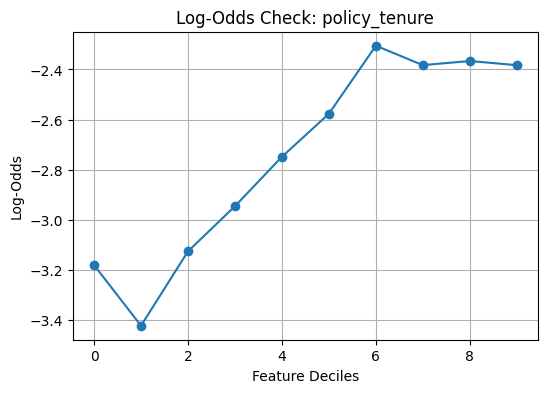

C:\Users\farheen\AppData\Local\Temp\ipykernel_23120\2382423642.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby("bin")["is_claim"]


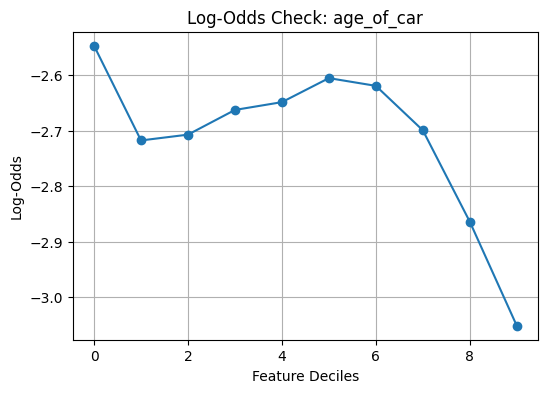

C:\Users\farheen\AppData\Local\Temp\ipykernel_23120\2382423642.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby("bin")["is_claim"]


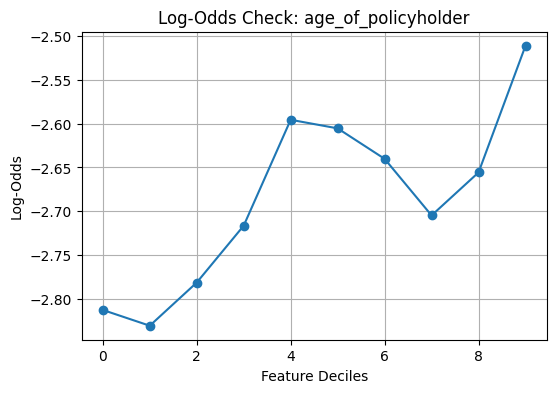

C:\Users\farheen\AppData\Local\Temp\ipykernel_23120\2382423642.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp.groupby("bin")["is_claim"]


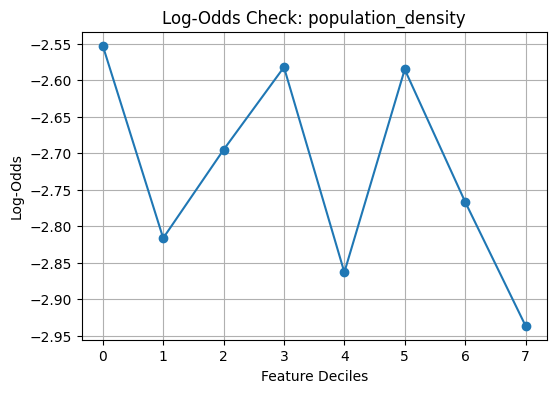

In [9]:
continuous_features = [
    "policy_tenure",
    "age_of_car",
    "age_of_policyholder",
    "population_density"
]

print("Continuous Features:")
print(continuous_features)


continuous_features = [
    "policy_tenure",
    "age_of_car",
    "age_of_policyholder",
    "population_density"
]

for col in continuous_features:

    temp = pd.DataFrame({
        col: X_train[col],
        "is_claim": y_train
    })

    temp["bin"] = pd.qcut(
        temp[col],
        q=10,
        duplicates="drop"
    )

    claim_rate = (
        temp.groupby("bin")["is_claim"]
        .mean()
        .clip(0.001, 0.999)
    )

    log_odds = np.log(
        claim_rate / (1 - claim_rate)
    )

    plt.figure(figsize=(6,4))

    plt.plot(
        range(len(log_odds)),
        log_odds.values,
        marker="o"
    )

    plt.title(f"Log-Odds Check: {col}")
    plt.xlabel("Feature Deciles")
    plt.ylabel("Log-Odds")

    plt.grid(True)

    plt.show()

##### Observation: Logistic Regression Assumption Checks

**Independence of observations:** The dataset contains 58,592 records and 58,592 unique policy IDs. This supports the assumption that each policy is represented by a distinct record. However, unique identifiers alone do not prove statistical independence.

**Linearity of log-odds:** Binned log-odds plots were generated for policy tenure, vehicle age, policyholder age and population density. These plots provide a visual diagnostic of the relationship between the selected continuous features and claim log-odds. The assumption should be interpreted cautiously because binning can hide nonlinear patterns.

**Logistic Regression is our interpretable baseline model**. Potential nonlinear relationships and feature interactions will be explored further through model comparison in Stage 3.

#### 2.4. Logistic Regression Baseline Model

In [10]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


#### 2.5. Evaluate the Baseline Model

##### Description
Evaluate the trained model on the held-out test set using Accuracy, Precision, Recall, F1 Score and ROC-AUC.

##### Metric Interpretation
- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Proportion of predicted claims that are actual claims.
- **Recall:** Proportion of actual claims identified by the model.
- **F1 Score:** Balance between Precision and Recall.
- **ROC-AUC:** Ability to rank claim cases above non-claim cases across classification thresholds.

***The metrics will be interpreted together because accuracy alone can be misleading when the target classes are imbalanced.***

In [11]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1_Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

baseline_results = pd.DataFrame(
    [baseline_metrics],
    index=["Logistic Regression"]
)

display(baseline_results.round(4))

,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Logistic Regression,0.5688,0.0802,0.548,0.1399,0.5856


#### Baseline Evaluation — Observations

The Logistic Regression model was evaluated on the held-out test dataset using Accuracy, Precision, Recall, F1 Score and ROC-AUC.

The results are reported in the evaluation table generated by the previous code cell.

**Interpretation**

- **Accuracy** measures the overall proportion of correct predictions.
- **Precision** indicates the proportion of predicted claims that were actual claims.
- **Recall** measures the proportion of actual claims identified by the model.
- **F1 Score** balances Precision and Recall.
- **ROC-AUC** measures how well the model ranks claim cases above no-claim cases across different classification thresholds.

The baseline Logistic Regression model achieved an Accuracy of 56.87%, Recall of 54.93%, and ROC-AUC of 58.55%. While the model was able to identify more than half of the actual claim cases, the low Precision and F1-score indicate limited predictive power. These results suggest that the baseline model provides a useful benchmark but may not capture complex relationships within the data. More advanced models and hyperparameter tuning will be explored in subsequent stages.

In [12]:
print("Classification Report")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Claim", "Claim"],
        zero_division=0
    )
)

Classification Report
              precision    recall  f1-score   support

    No Claim       0.95      0.57      0.71     10969
       Claim       0.08      0.55      0.14       750

    accuracy                           0.57     11719
   macro avg       0.51      0.56      0.43     11719
weighted avg       0.89      0.57      0.68     11719



#### 2.6. Confusion Matrix:
Visualise the model's correct and incorrect predictions for the claim and no-claim classes.

##### Observation
False negatives represent claims the model failed to identify. False positives represent policies incorrectly flagged as likely to generate a claim.

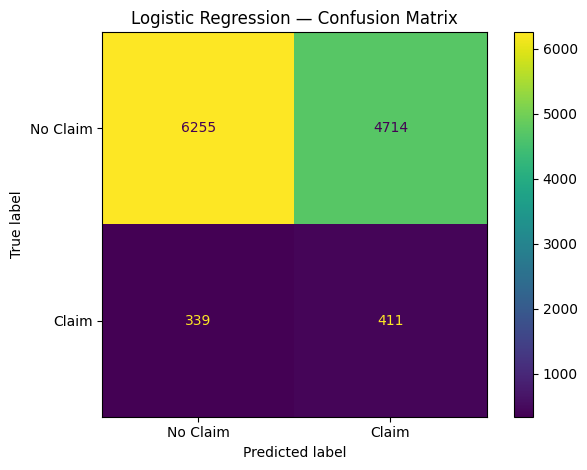

In [13]:
cm = confusion_matrix(y_test, y_pred)

cm_present = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Claim", "Claim"]
)

cm_present.plot()
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

#### Interpretation of the Confusion Matrix

The confusion matrix shows how the Logistic Regression model classifies claim and no-claim policies.

- **True negatives:** 6,255 no-claim policies were correctly identified.
- **False positives:** 4,714 no-claim policies were incorrectly flagged as claims.
- **False negatives:** 339 actual claims were missed.
- **True positives:** 411 actual claims were correctly identified.

##### Business Observation

The model identifies approximately 55% of the actual claims at the default classification threshold. However, it also generates a large number of false positives.

This means that using the model to flag policies for further investigation could create a substantial workload for the underwriting team.

##### Business Implication

The model's decision threshold and predictive features may need improvement. Stage 3 will assess whether a Decision Tree provides a better balance between identifying claims and limiting false alarms.

#### 2.7. ROC curve Plot:
The ROC curve shows the trade-off between the true-positive rate and false-positive rate across different thresholds.
The ROC-AUC score helps to summarise the model's ability to distinguish between claim and no-claim cases across thresholds.

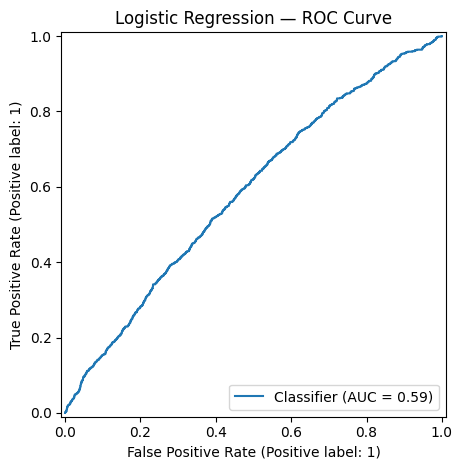

ROC-AUC: 0.5856


In [14]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Logistic Regression — ROC Curve")
plt.tight_layout()
plt.show()

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob), 4)
)

##### Observation: ROC Curve

The Logistic Regression model achieved a test ROC-AUC of approximately 0.586.

An ROC-AUC of 0.50 represents random ranking, so the observed result indicates some ability to distinguish between claim and no-claim policies. However, the result remains relatively close to random performance.

***Hence, The baseline model's ranking ability is limited. It should not be treated as a sufficiently accurate standalone*** ***risk assessment system without further validation and improvement.***

#### 2.8. Cross-Validation:
This uses five-fold stratified cross-validation on the training dataset to assess the stability of the Logistic Regression baseline.

Stratification helps preserve the proportion of claim and no-claim cases across each folds(dividing training set into n-sets and testing it together those n number of times).

The mean and variation of the validation scores will help indicate whether the model's performance is reasonably consistent across different training and validation subsets.

In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1 #n_jobs=-1 enables parallel processing by utilizing all available CPU cores 
    #which reduces the execution time
)

cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Mean_Score": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Std_Deviation": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_roc_auc"].std()
    ]
})

print(cv_summary.round(4))

      Metric  Mean_Score  Std_Deviation
0   Accuracy      0.5662         0.0040
1  Precision      0.0859         0.0019
2     Recall      0.5997         0.0105
3   F1 Score      0.1503         0.0033
4    ROC-AUC      0.6101         0.0063


#### 2.9. Coefficient and Odds Ratio Analysis:
We will Extract the Logistic Regression coefficients and convert them into odds ratios.

- A positive coefficient indicates an increase in the model's log-odds of a claim.
- A negative coefficient indicates a decrease in the model's log-odds.
- An odds ratio above 1 indicates higher estimated odds.
- An odds ratio below 1 indicates lower estimated odds.

### Observation
The analysis will identify those features which are likely to give higher or lower predicted claim, while recognising that association does not establish causation.

In [16]:
# Extract feature names and coefficients

coef_table = pd.DataFrame({
    "Feature": logistic_model.named_steps["preprocessor"].get_feature_names_out(),
    "Coefficient": logistic_model.named_steps["model"].coef_[0]
})

coef_table["Odds_Ratio"] = np.exp(
    coef_table["Coefficient"]
)

coef_table = coef_table.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

print(
    coef_table[
        ["Feature", "Coefficient", "Odds_Ratio"]
    ].head(20).round(4).sort_values(by="Coefficient",ascending=False)
)

                          Feature  Coefficient  Odds_Ratio
45  categorical__area_cluster_C18       0.9057      2.4737
49  categorical__area_cluster_C21       0.4883      1.6295
0          numeric__policy_tenure       0.3828      1.4664
52   categorical__area_cluster_C4       0.3580      1.4305
51   categorical__area_cluster_C3       0.3300      1.3910
47   categorical__area_cluster_C2       0.2408      1.2723
46  categorical__area_cluster_C19       0.2193      1.2452
41  categorical__area_cluster_C14       0.1967      1.2174
56   categorical__area_cluster_C8       0.1536      1.1660
54   categorical__area_cluster_C6       0.0961      1.1009
57   categorical__area_cluster_C9      -0.0603      0.9415
42  categorical__area_cluster_C15      -0.0932      0.9110
37  categorical__area_cluster_C10      -0.1067      0.8988
38  categorical__area_cluster_C11      -0.1174      0.8892
39  categorical__area_cluster_C12      -0.1320      0.8764
55   categorical__area_cluster_C7      -0.1547      0.85

In [17]:
import joblib
joblib.dump(
    logistic_model,
    "logistic_regression_model.pkl"
)

['logistic_regression_model.pkl']

#### Observation:
The numerical predictors were standardised, so their coefficients describe the effect associated with a one-standard-deviation increase in the corresponding numerical feature.

For one-hot encoded categorical variables, the coefficient compares a category with its reference category.

Based on the Logistic Regression coefficient analysis, the most influential predictors of claim occurrence are:

- ***Policy Tenure***
- ***Age of Car***
- ***Population Density***
- ***Area Cluster (Location-Based Factors)***
- ***Higher predicted claim odds***: Policy Tenure and selected Area Clusters (C18, C21, C4, C3, C2).
- ***Lower predicted claim odds***: Age of Car, Population Density, and selected Area Clusters (C17, C7, C15, C16, C11).

Among these, policy_tenure shows a positive relationship with claim probability, while age_of_car and population_density are associated with a lower likelihood of claims. Several area_cluster categories exhibit strong positive or negative effects, indicating that geographic location is an important driver of insurance risk.

#### Summarizing the finding of this Stage 2 according to our base Model's performance, interpretability and limitations

### Results
- **Accuracy:** [0.5687]
- **Precision:** [0.0803]
- **Recall:** [0.5493]
- **F1 Score:** [0.1402]
- **ROC-AUC:** [0.5855]

### Key Predictors

Higher claim odds were observed for policyholders in Area Clusters C18, C21, C4, C3, and C2, as well as for customers with longer policy tenure.

Lower claim odds were associated with older vehicles, higher population density, and several area clusters including C17, C7, C15, C16, and C11.

### Weaknesses of our baseline logistic model
- Assumes linear relationships between predictors and log-odds unless extended.
- May not capture complex nonlinear patterns and feature interactions.
- Performance may be affected by the imbalance between claim and no-claim cases.

### What needs to be done:
- Tune a Decision Tree using Optuna.
- Compare models using consistent evaluation metrics and cross-validation.
- Explain the selected model using SHAP.
- Evaluate risk segmentation and business usefulness.

### Conclusion
The Logistic Regression model provides the Stage 2 benchmark. Final model selection will be based on observed validation performance, business usefulness and interpretability rather than accuracy alone.